# PHYS 311 — Lab 7: Python Physics Engine Prototype

This lab follows the **Week 7 engine lesson notebook**. The engine lives in `lab07_engine/engine.py`, and this notebook uses it without writing new physics loops for each scene. Units are consistent within each simulation.

In [1]:
import os
os.chdir(r"C:\Users\blann\Downloads\PHYS311\phys311\labs\lab07")

import numpy as np
import matplotlib.pyplot as plt

from lab07_engine.engine import (
    Body, Gravity, Drag, Spring, NewtonGravity,
    EulerCromer, VelocityVerlet, World
)

## Part A — Core engine (35 points)

The engine has the four components required by the lesson. `World` owns the bodies, forces, integrator and clock. It clears force accumulators, applies the registered forces, integrates using a fixed timestep, and records quantities to plot. `VelocityVerlet` is included because the Week 7 reference uses it to validate orbits.

```mermaid
flowchart TD
    W[World] --> B[Body]
    W --> F[Forces: Gravity, Drag, Spring, NewtonGravity]
    W --> I[Integrators: EulerCromer, VelocityVerlet]
    W --> R[Recorded history]
```

The collision stage is not implemented here because Part B uses an orbit for the third validation and Part C uses spring interactions, not impacts.

In [2]:
# Quick test of the world and its recorder
w = World(EulerCromer())
w.add_body(Body(1, [0, 1], [1, 2]))
w.add_force(Gravity())
w.record('time', lambda W: W.time)
w.record('position', lambda W: W.bodies[0].r.copy())
w.record('energy', lambda W: W.total_energy())
w.record('momentum', lambda W: W.momentum().copy())
h = w.run(0.01, 0.1)
print('Recorded positions:', h['position'].shape)
print('Recorded energy values:', len(h['energy']))


Recorded positions: (11, 2)
Recorded energy values: 11


## Part B — Validate three earlier labs (35 points)

### B1: Projectile motion (Labs 1–2)

Use gravity only and compare the engine's trajectory to the known constant-acceleration equations. Total energy should remain nearly constant because there is no drag.

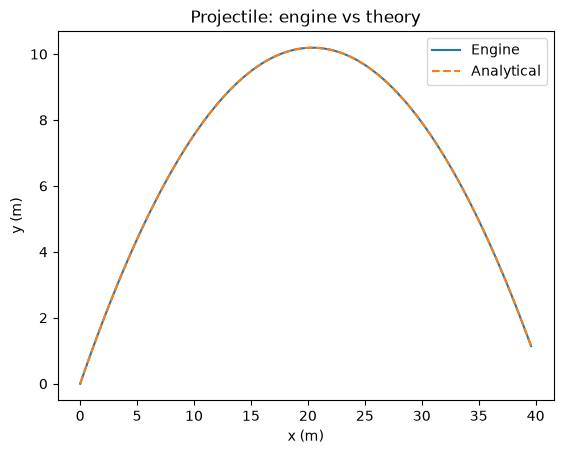

Largest height difference (m): 2.5779378631796135e-13
Maximum energy change (J): 3.694822225952521e-13


In [3]:
v0 = 20.0
angle = np.radians(45)
g = 9.81
w = World(VelocityVerlet())
w.add_body(Body(1, [0, 0], [v0*np.cos(angle), v0*np.sin(angle)]))
w.add_force(Gravity(g))
w.record('time', lambda W: W.time)
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
w.record('energy', lambda W: W.total_energy())
h = w.run(0.01, 2.8)
t = h['time']
x_theory = v0*np.cos(angle)*t
y_theory = v0*np.sin(angle)*t - 0.5*g*t**2
mask = y_theory >= 0
plt.plot(h['x'][mask], h['y'][mask], label='Engine')
plt.plot(x_theory[mask], y_theory[mask], '--', label='Analytical')
plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.title('Projectile: engine vs theory')
plt.legend(); plt.show()
print('Largest height difference (m):', np.max(np.abs(h['y']-y_theory)))
print('Maximum energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))


**Observation:** The simulated trajectory overlaps the analytical parabola. Mechanical energy (kinetic plus gravitational potential) should remain nearly constant. This checks the gravity force and time integrator.

### B2: Spring oscillator (Lab 3)

Connect a moving mass to a fixed support using the lesson's `Spring` force. Compare with the simple harmonic motion solution, \(x(t)=x_0\cos(\sqrt{k/m}\,t)\). The spring potential energy is included in the engine.

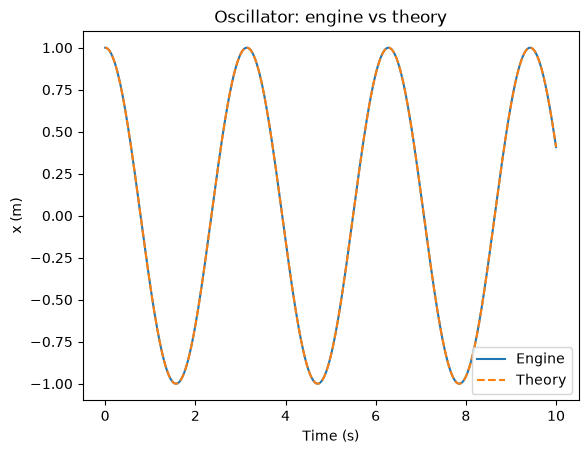

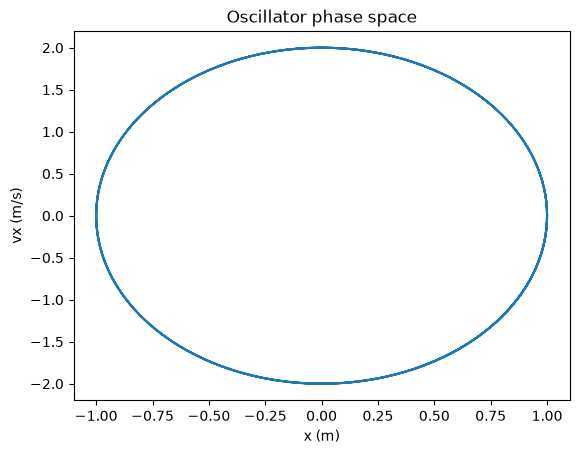

Largest displacement difference (m): 0.0003043514465068675
Maximum energy change (J): 0.000199999532787265


In [4]:
m = 1.0
k = 4.0
w = World(VelocityVerlet())
w.add_body(Body(m, [0, 0], [0, 0], fixed=True))
w.add_body(Body(m, [1, 0], [0, 0]))
w.add_force(Spring(0, 1, k=k, L0=0))
w.record('time', lambda W: W.time)
w.record('x', lambda W: W.bodies[1].r[0])
w.record('vx', lambda W: W.bodies[1].v[0])
w.record('energy', lambda W: W.total_energy())
h = w.run(0.01, 10)
x_theory = np.cos(np.sqrt(k/m)*h['time'])
plt.plot(h['time'], h['x'], label='Engine')
plt.plot(h['time'], x_theory, '--', label='Theory')
plt.xlabel('Time (s)'); plt.ylabel('x (m)'); plt.title('Oscillator: engine vs theory')
plt.legend(); plt.show()
plt.plot(h['x'], h['vx'])
plt.xlabel('x (m)'); plt.ylabel('vx (m/s)'); plt.title('Oscillator phase space')
plt.show()
print('Largest displacement difference (m):', np.max(np.abs(h['x']-x_theory)))
print('Maximum energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))


**Observation:** The engine follows the cosine solution and produces the expected elliptical phase-space curve. The oscillating spring exchanges kinetic and potential energy while total energy stays nearly constant.

### B3: Circular orbit (Lab 5)

Use `NewtonGravity` and `VelocityVerlet` from the lesson. Set \(G=M=r=1\), so the circular orbital speed is approximately \(v=1\). Compare the simulated orbit with the known unit circle and check energy and angular momentum.

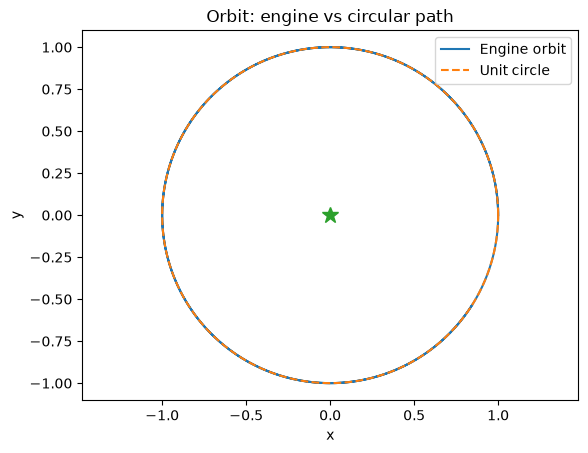

Largest radius deviation: 1.2499921749231646e-05
Maximum relative energy change: 1.5624459191732054e-10
Maximum relative angular momentum change: 1.734723475976807e-15


In [5]:
w = World(VelocityVerlet())
w.add_body(Body(1.0, [0, 0], [0, 0], fixed=True))
w.add_body(Body(0.001, [1, 0], [0, 1]))
w.add_force(NewtonGravity(G=1.0))
w.record('x', lambda W: W.bodies[1].r[0])
w.record('y', lambda W: W.bodies[1].r[1])
w.record('energy', lambda W: W.total_energy())
w.record('L', lambda W: W.bodies[1].m*(W.bodies[1].r[0]*W.bodies[1].v[1] - W.bodies[1].r[1]*W.bodies[1].v[0]))
h = w.run(0.005, 12)
theta = np.linspace(0, 2*np.pi, 300)
plt.plot(h['x'], h['y'], label='Engine orbit')
plt.plot(np.cos(theta), np.sin(theta), '--', label='Unit circle')
plt.plot(0, 0, '*', markersize=12)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.title('Orbit: engine vs circular path')
plt.legend(); plt.show()
print('Largest radius deviation:', np.max(np.abs(np.sqrt(h['x']**2+h['y']**2)-1)))
print('Maximum relative energy change:', np.max(np.abs(h['energy']-h['energy'][0]))/abs(h['energy'][0]))
print('Maximum relative angular momentum change:', np.max(np.abs(h['L']-h['L'][0]))/abs(h['L'][0]))


**Observation:** The orbit remains close to circular, with small numerical changes in total energy and angular momentum. The planet is slightly attracted toward the fixed star; the finite mass ratio makes the exact circular speed slightly different from 1, explaining a small mismatch.

## Part C — Original multi-body scene (30 points)

### Three hanging masses connected by springs

This original scene uses **four bodies**: one fixed support and three moving masses. Each adjacent pair is connected by a spring, and all moving masses experience uniform gravity. The forces are therefore `Spring` and `Gravity`, exactly like the force registry in the reference. The masses start slightly off-center to produce a swinging, coupled motion. The fixed support supplies an external reaction force, so total momentum of the moving masses is **not** conserved; mechanical energy should remain approximately conserved because no drag is present.

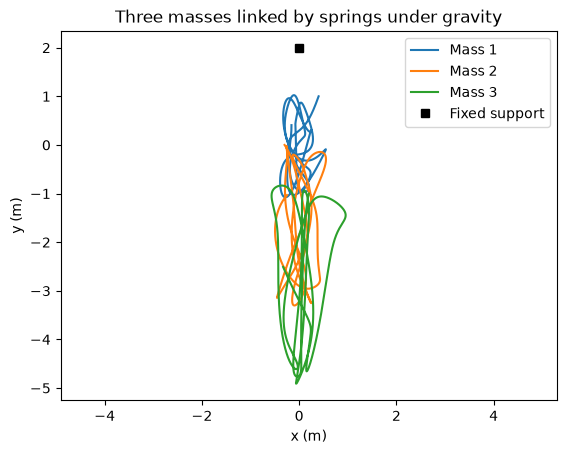

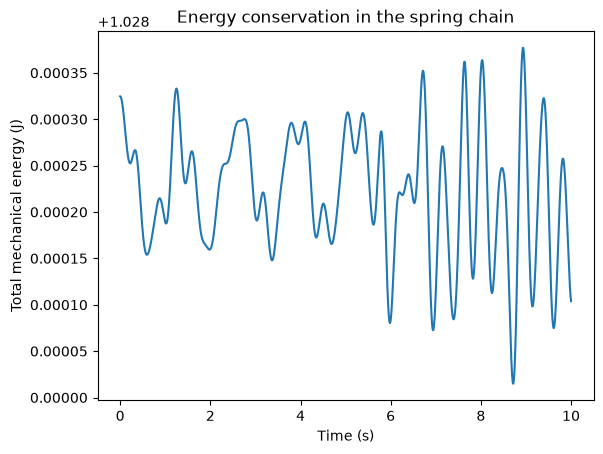

Maximum mechanical energy change (J): 0.0003097456073031246
Relative energy change: 0.0003012138316996083


In [6]:
w = World(VelocityVerlet())
w.add_body(Body(1, [0, 2], [0, 0], fixed=True))
w.add_body(Body(1, [0.4, 1], [0, 0]))
w.add_body(Body(1, [-0.3, 0], [0, 0]))
w.add_body(Body(1, [0.2, -1], [0, 0]))
w.add_force(Gravity(9.81))
w.add_force(Spring(0, 1, k=30, L0=1))
w.add_force(Spring(1, 2, k=30, L0=1))
w.add_force(Spring(2, 3, k=30, L0=1))
w.record('time', lambda W: W.time)
w.record('energy', lambda W: W.total_energy())
for i in range(1, 4):
    w.record(f'x{i}', lambda W, i=i: W.bodies[i].r[0])
    w.record(f'y{i}', lambda W, i=i: W.bodies[i].r[1])
h = w.run(0.002, 10)
for i in range(1, 4):
    plt.plot(h[f'x{i}'], h[f'y{i}'], label=f'Mass {i}')
plt.plot(0, 2, 'ks', label='Fixed support')
plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.title('Three masses linked by springs under gravity')
plt.axis('equal'); plt.legend(); plt.show()
plt.plot(h['time'], h['energy'])
plt.xlabel('Time (s)'); plt.ylabel('Total mechanical energy (J)')
plt.title('Energy conservation in the spring chain'); plt.show()
print('Maximum mechanical energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))
print('Relative energy change:', np.max(np.abs(h['energy']-h['energy'][0]))/abs(h['energy'][0]))


**Part C explanation:** The three masses move together because the spring forces depend on the distance between neighboring masses. Gravity pulls each moving mass down while spring forces oppose stretching and compression. The trajectories are coupled rather than three separate single-mass oscillations. The nearly constant total mechanical energy indicates that the simulation is behaving correctly: with no drag, energy is exchanged between kinetic, spring potential, and gravitational potential forms. Momentum is not expected to be constant because the fixed support exerts an external force.

## Conclusion

I assembled the same `Body` / `Force` / `Integrator` / `World` structure taught in Week 7 and used it for four simulations without rewriting the core engine. The three comparisons in Part B check the force laws, integration, and conservation behavior. Part C shows how combining existing parts can produce a more complex multi-body scene.